In [2]:
import os

from cil.io import NikonDataReader, TIFFWriter
from cil.processors import (
    Binner,
    CentreOfRotationCorrector,
    Slicer,
    TransmissionAbsorptionConverter,
)
from cil.recon import FDK
from cil.utilities.display import show2D, show_geometry
from cil.utilities.jupyter import islicer

from comptest.constants import DATASETS_PROJECTIONS_DIR, DATASETS_RECONSTRUCTIONS_DIR

In [3]:
import logging

logging.basicConfig(level=logging.WARNING)
cil_log_level = logging.getLogger("cil.processors")
cil_log_level.setLevel(logging.INFO)

In [4]:
DATASET = "Canislupus_CZM_712"
PROJECTION_FILENAME = "Canislupus_CZM_712.xtekct"

PROJECTIONS_FILE = DATASETS_PROJECTIONS_DIR / DATASET / PROJECTION_FILENAME

Number of dimensions: 3
Shape: (1571, 2000, 2000)
Axis labels: (<AcquisitionDimension.ANGLE: 'angle'>, <AcquisitionDimension.VERTICAL: 'vertical'>, <AcquisitionDimension.HORIZONTAL: 'horizontal'>)

3D Cone-beam tomography
System configuration:
	Source position: [   0.        , -673.21926117,    0.        ]
	Rotation axis position: [-0.,  0.,  0.]
	Rotation axis direction: [0., 0., 1.]
	Detector position: [ -0.        , 441.71773883,   0.        ]
	Detector direction x: [1., 0., 0.]
	Detector direction y: [0., 0., 1.]
Panel configuration:
	Number of pixels: [2000 2000]
	Pixel size: [0.2 0.2]
	Pixel origin: top-right
Channel configuration:
	Number of channels: 1
Acquisition description:
	Number of positions: 1571
	Angles 0-9 in degrees: [-178.0625 , -178.29166, -178.52081, -178.75   , -178.97916, -179.20831,
 -179.43747, -179.66663, -179.89581, -180.12497]
	Angles 1561-1570 in degrees: [-535.78503, -536.01416, -536.24335, -536.47253, -536.70166, -536.93085,
 -537.16003, -537.38916, -537.

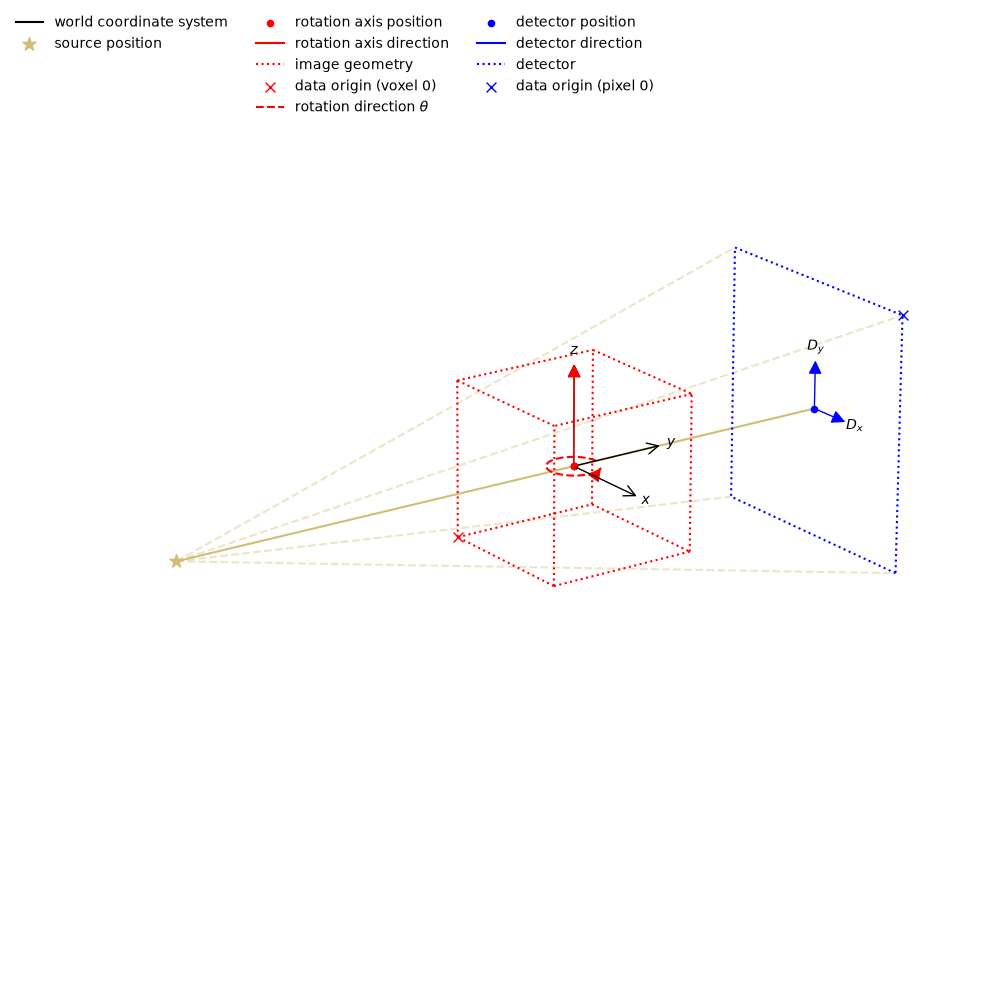

In [5]:
# read in the data from the Nikon `xtekct` file
data_in = NikonDataReader(file_name=PROJECTIONS_FILE).read()

# print the meta data associated with the data
print(data_in)

# print the geometry data associated with the data
print(data_in.geometry)

# display the geometry
show_geometry(data_in.geometry)

In [6]:
islicer(data_in, direction="angle", size=10, origin="upper")

INFO:cil.processors.TransmissionAbsorptionConverter:
 Current min_intensity = 0.0: output may contain NaN or inf. Ensure your data only contains positive values or set min_intensity to a small positive value.


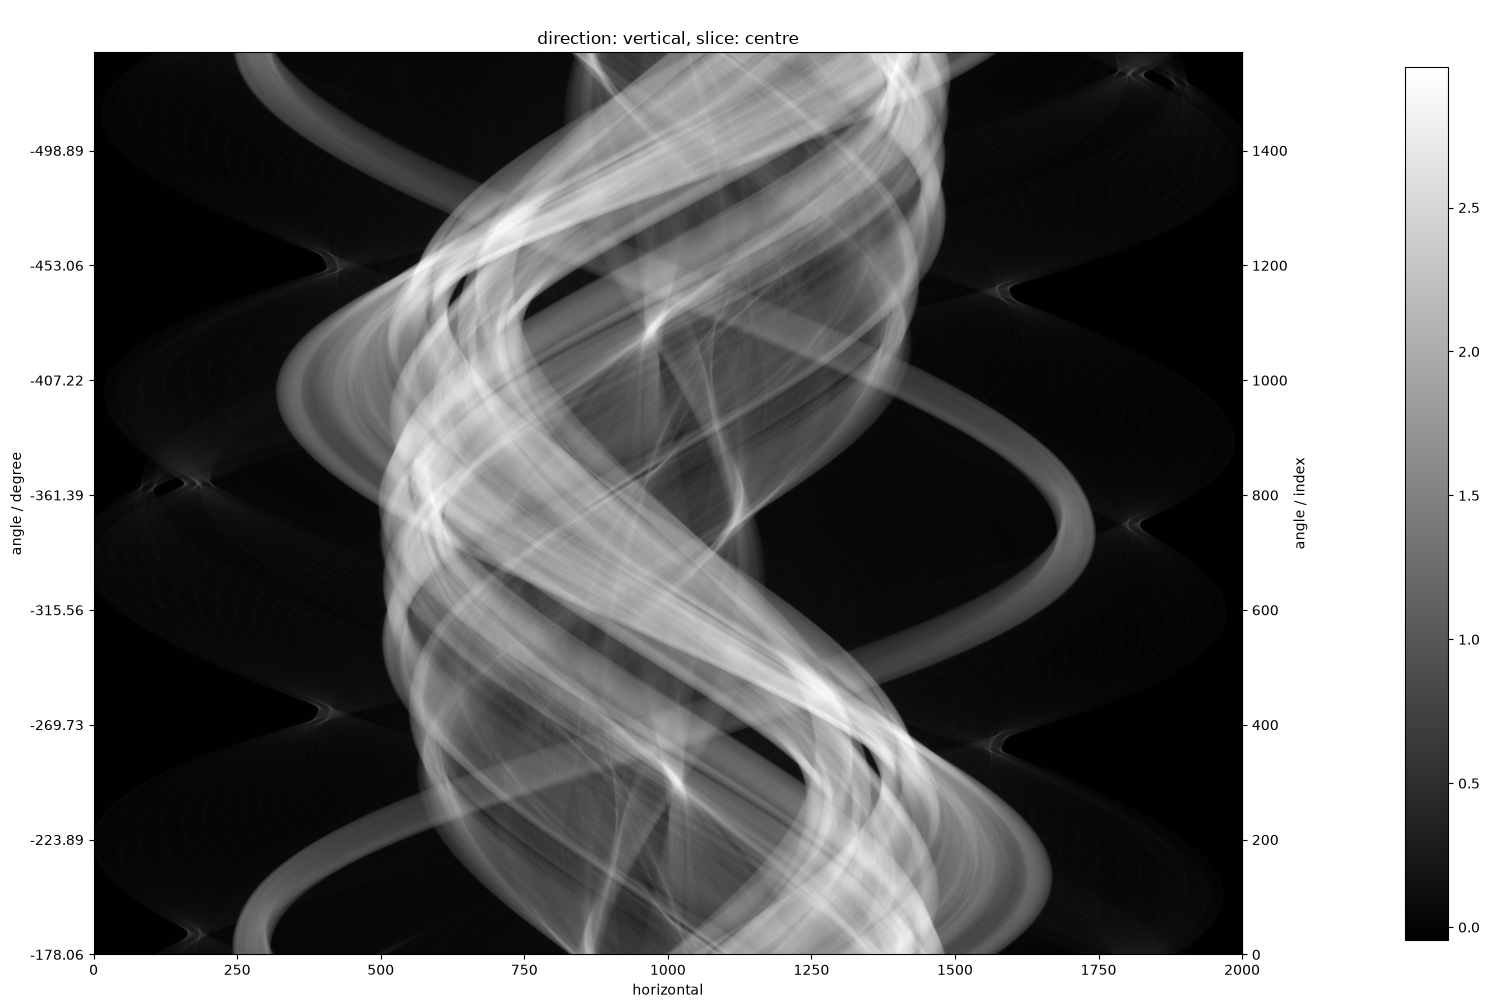

In [7]:
# calculate the absorption data using the Beer–Lambert law
data_absorption = TransmissionAbsorptionConverter()(data_in)

# show the centre slice using show2D
show2D(data_absorption, slice_list=("vertical", "centre"))

In [8]:
# reorder the data for the `tigre` backend
data_absorption.reorder(order="tigre")

# create a default image geometry to define the reconstruction volume
ig = data_absorption.geometry.get_ImageGeometry()

# create the FDK reconstructor
fdk = FDK(data_absorption, ig)

# run the reconstructor
recon = fdk.run()

# visualise the 3D reconstructed volume
islicer(
    recon, direction="vertical", size=10
)  # change to 'horizontal_y' or 'horizontal_x' to view the data in other directions

FDK recon

Input Data:
	angle: 1571
	vertical: 2000
	horizontal: 2000

Reconstruction Volume:
	vertical: 2000
	horizontal_y: 2000
	horizontal_x: 2000

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 12
	Filter_inplace: False



Number of channels: 1
channel_spacing: 1.0
voxel_num : x2000,y2000,z2000
voxel_size : x0.12076364156350254,y0.12076364156350254,z0.12076364156350254
center : x0,y0,z0



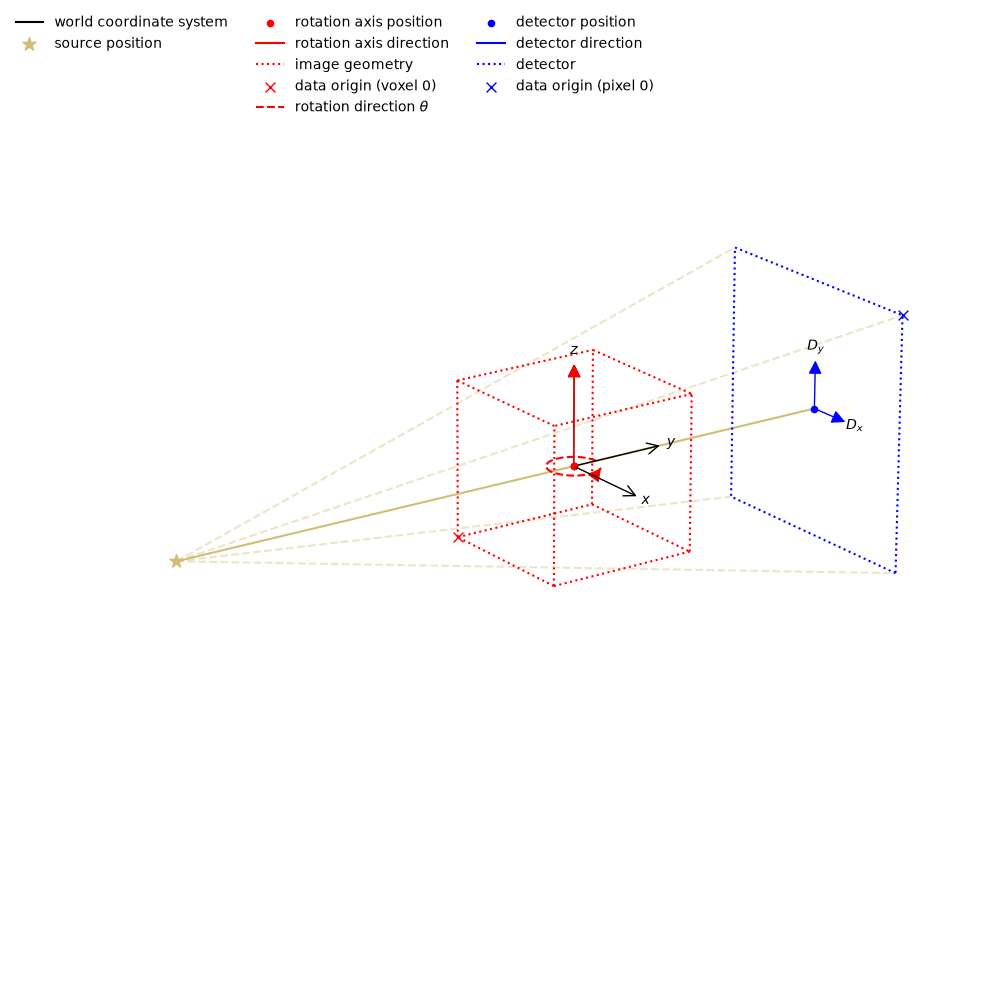

In [9]:
print(data_absorption.geometry.get_ImageGeometry())
show_geometry(data_absorption.geometry, data_absorption.geometry.get_ImageGeometry())

INFO:cil.processors.CofR_image_sharpness:evaluated 11 points
INFO:cil.processors.CofR_image_sharpness:evaluated 11 points
INFO:cil.processors.CofR_image_sharpness:Centre of rotation correction found using image_sharpness
INFO:cil.processors.CofR_image_sharpness:backend FBP/FDK tigre
INFO:cil.processors.CofR_image_sharpness:Calculated from slice: centre
INFO:cil.processors.CofR_image_sharpness:Centre of rotation shift = 6.449878 pixels
INFO:cil.processors.CofR_image_sharpness:Centre of rotation shift = 0.778911 units at the object
INFO:cil.processors.CofR_image_sharpness:Return new dataset with centred geometry


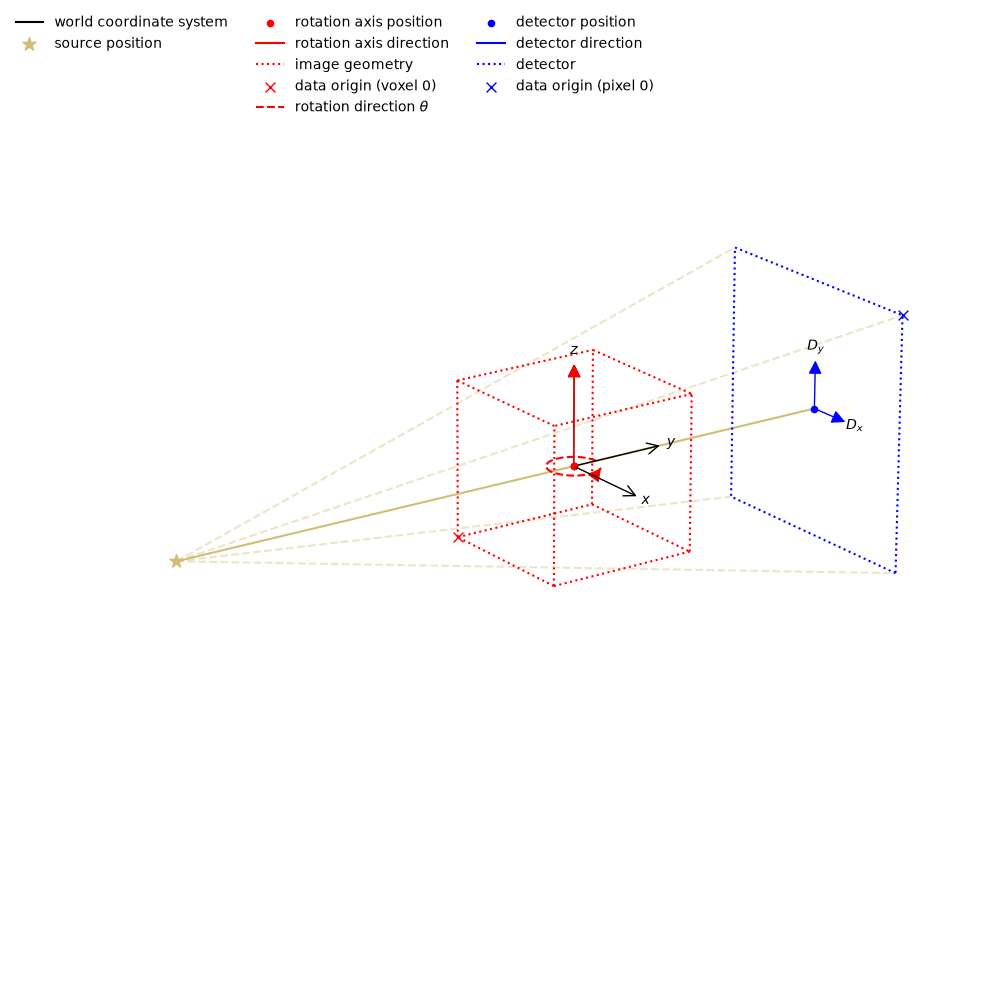

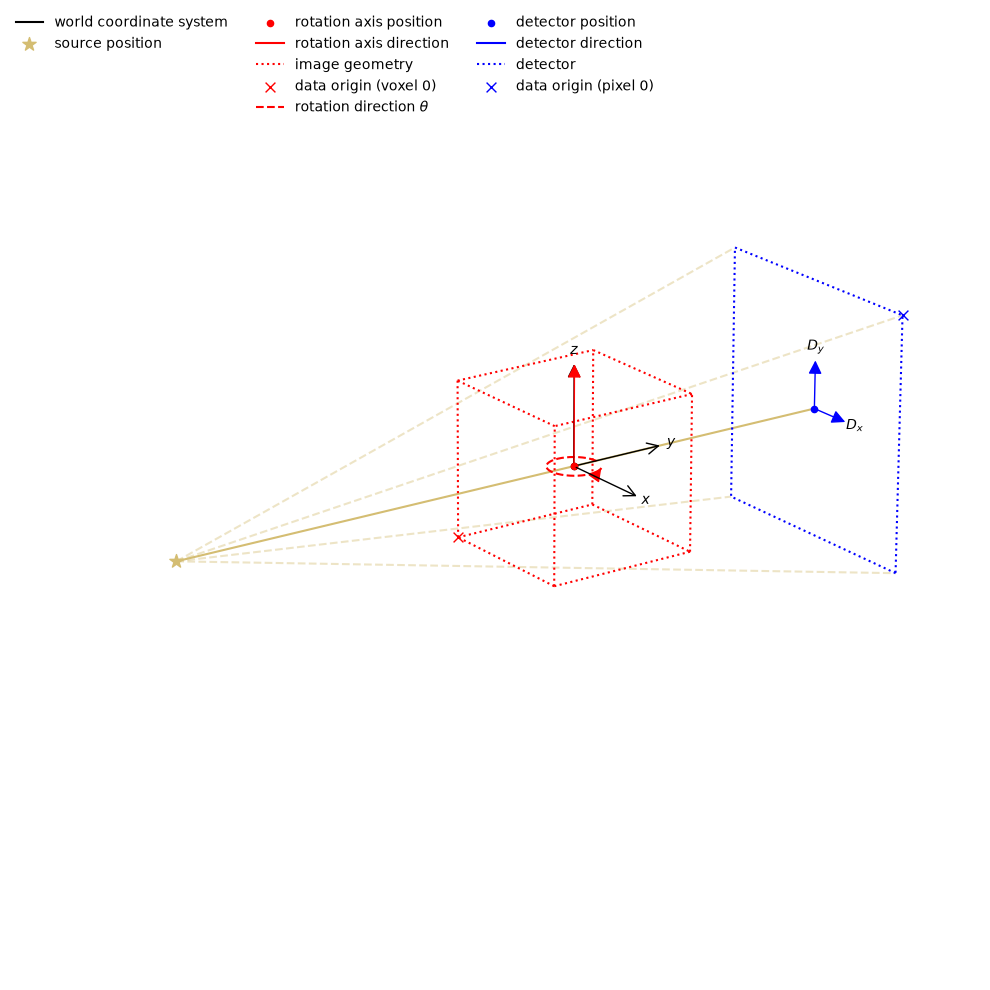

3D Cone-beam tomography
System configuration:
	Source position: [   0.        , -673.21926117,    0.        ]
	Rotation axis position: [-0.,  0.,  0.]
	Rotation axis direction: [0., 0., 1.]
	Detector position: [ -0.        , 441.71773883,   0.        ]
	Detector direction x: [1., 0., 0.]
	Detector direction y: [0., 0., 1.]
Panel configuration:
	Number of pixels: [2000 2000]
	Pixel size: [0.2 0.2]
	Pixel origin: top-right
Channel configuration:
	Number of channels: 1
Acquisition description:
	Number of positions: 1571
	Angles 0-9 in degrees: [-178.0625 , -178.29166, -178.52081, -178.75   , -178.97916, -179.20831,
 -179.43747, -179.66663, -179.89581, -180.12497]
	Angles 1561-1570 in degrees: [-535.78503, -536.01416, -536.24335, -536.47253, -536.70166, -536.93085,
 -537.16003, -537.38916, -537.6183 , -537.84753]
	Full angular array can be accessed with acquisition_data.geometry.angles
Distances in units: units distance
3D Cone-beam tomography
System configuration:
	Source position: [   0.

In [10]:
# Run `image_sharpness` on the dataset and return a new dataset with a new geometry.
data_centred = CentreOfRotationCorrector.image_sharpness(
    backend="tigre", search_range=100, tolerance=0.1
)(data_absorption)
# From the logging, we can see that the centre of rotation offset is 4.8 pixels. Therefore it isn't noticeable when we use show_geometry.

# show the original geometry
show_geometry(data_absorption.geometry)

# show the centred geometry
show_geometry(data_centred.geometry)

# print the original geometry
print(data_absorption.geometry)

# print the new geometry
print(data_centred.geometry)

In [11]:
# reorder the data for the `tigre` backend
data_centred.reorder(order="tigre")

# create the FDK reconstructor
fdk = FDK(data_centred, ig)

# run the reconstructor
recon_full = fdk.run()

# visualise the 3D reconstructed volume
islicer(
    recon_full, direction="vertical", size=10
)  # change to 'horizontal_y' or 'horizontal_x' to view the data in other directions

FDK recon

Input Data:
	angle: 1571
	vertical: 2000
	horizontal: 2000

Reconstruction Volume:
	vertical: 2000
	horizontal_y: 2000
	horizontal_x: 2000

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 12
	Filter_inplace: False



In [ ]:
# Save full reconstruction
output_dir = DATASETS_RECONSTRUCTIONS_DIR / "CIL_basic" / DATASET
output_dir.mkdir(parents=True, exist_ok=True)

writer = TIFFWriter(data=recon_full, file_name=output_dir / DATASET)
writer.write()

In [ ]:
data_binned_2x2 = Binner(
    roi={"horizontal": (None, None, 2), "vertical": (None, None, 2)}
)(data_in)
show2D(data_binned_2x2)

data_binned_absorption = TransmissionAbsorptionConverter()(data_binned_2x2)

data_binned_2x2_centred = CentreOfRotationCorrector.image_sharpness()(
    data_binned_absorption
)
# notice the offset is approximately the same in mm as calculated on the un-binned data, but the offset in pixels is now 1/4 of the value


data_binned_2x2_centred.reorder(order="tigre")
fdk = FDK(data_binned_2x2_centred)
recon_binned_2x2 = fdk.run()
islicer(
    recon_binned_2x2, direction="vertical", size=10
)  # change to 'horizontal_y' or 'horizontal_x' to view the data in other directions

In [15]:
# Save binned 2x2 reconstruction
output_dir = DATASETS_RECONSTRUCTIONS_DIR / "CIL_basic_binned_2x2" / DATASET
output_dir.mkdir(parents=True, exist_ok=True)

writer = TIFFWriter(data=recon_binned_2x2, file_name=output_dir / DATASET)
writer.write()

NameError: name 'recon_binned_2x2' is not defined

In [ ]:
data_binned_4x4 = Binner(
    roi={"horizontal": (None, None, 4), "vertical": (None, None, 4)}
)(data_in)
show2D(data_binned_4x4)

data_binned_absorption = TransmissionAbsorptionConverter()(data_binned_4x4)

data_binned_4x4_centred = CentreOfRotationCorrector.image_sharpness()(
    data_binned_absorption
)
# notice the offset is approximately the same in mm as calculated on the un-binned data, but the offset in pixels is now 1/4 of the value


data_binned_4x4_centred.reorder(order="tigre")
fdk = FDK(data_binned_4x4_centred)
recon_binned_4x4 = fdk.run()
islicer(
    recon_binned_4x4, direction="vertical", size=10
)  # change to 'horizontal_y' or 'horizontal_x' to view the data in other directions

In [ ]:
# Save binned 4x4 reconstruction
output_dir = DATASETS_RECONSTRUCTIONS_DIR / "CIL_binned_4x4" / DATASET
output_dir.mkdir(parents=True, exist_ok=True)

writer = TIFFWriter(data=recon_binned_4x4, file_name=output_dir / DATASET)
writer.write()